In [3]:
%pip install --no-cache-dir "numpy==1.26.4"

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.0/14.0 MB 7.3 MB/s  0:00:01 eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlflow 2.14.3 requires packaging<25, but you have packaging 26.0 which is incompatible.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install scikit-image -q

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

NumPy: 1.26.4
Matplotlib: 3.8.1


In [2]:
# create a tiny grayscale image
image = np.array([
    [0, 0, 0, 0, 0],
    [0, 50, 100, 50, 0],
    [0, 100, 255, 100, 0],
    [0, 50, 100, 50, 0],
    [0, 0, 0, 0, 0],
], dtype = np.uint8)

print("Image shape: ", image.shape)
print("Pixel intensity range: ", image.min(), image.max())

Image shape:  (5, 5)
Pixel intensity range:  0 255


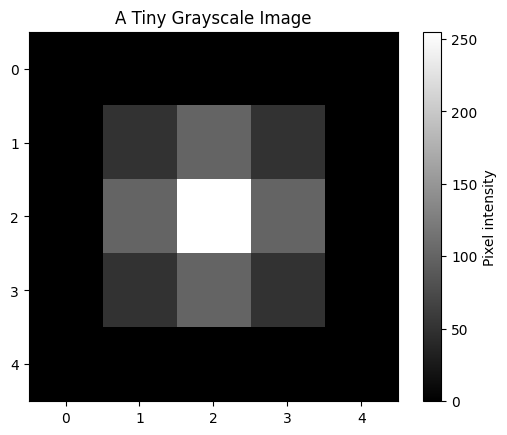

In [3]:
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.colorbar(label="Pixel intensity")
plt.title("A Tiny Grayscale Image")
plt.show()

# Each sqaure represents one pixel
# 255 - bright center (max value for an 8-bit grayscale image)
# 0 - dark black border

In [4]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [5]:
image_path = Path("../data/cross_section.png")
image = np.array(Image.open(image_path).convert("RGB"))

print("Image shape: ", image.shape)
print("Data type: ", image.dtype)
print("Minimum intensity: ", image.min())
print("Maximum intensity: ", image.max())

Image shape:  (492, 1272, 3)
Data type:  uint8
Minimum intensity:  0
Maximum intensity:  255


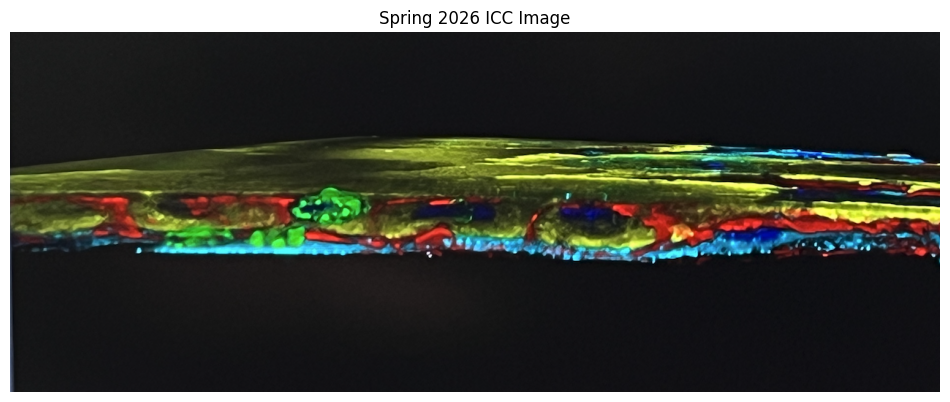

In [6]:
plt.figure(figsize=(12, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Spring 2026 ICC Image")
plt.show()

In [7]:
# Seperate the RGB channels
red = image[:, :, 0]
green = image[:, :, 1]
blue = image[:, :, 2]

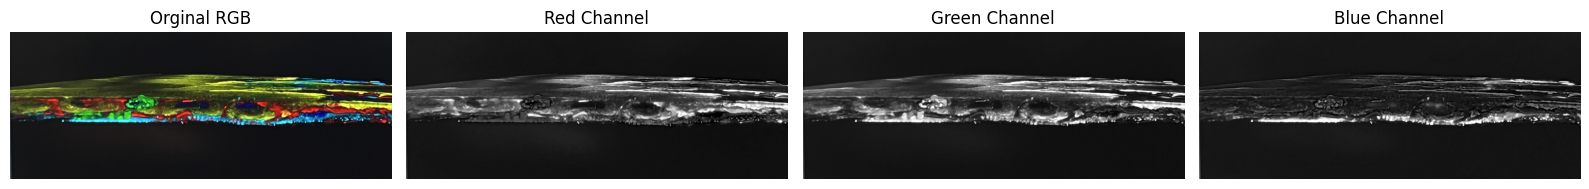

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image)
axes[0].set_title("Orginal RGB")

axes[1].imshow(red, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Red Channel")

axes[2].imshow(green, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Green Channel")

axes[3].imshow(blue, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Blue Channel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
# Calculate intensity statistics for each RGB channel
channels = {
    "Red": red,
    "Green": green,
    "Blue": blue
}

for name, channel in channels.items():
    print(f"{name} Channel: ")
    print(f" Min: {channel.min()}")
    print(f" Max: {channel.max()}")
    print(f" Mean: {channel.mean():.2f}")
    print(f" Std: {channel.std():.2f}")
    print()

Red Channel: 
 Min: 0
 Max: 255
 Mean: 38.20
 Std: 40.96

Green Channel: 
 Min: 0
 Max: 255
 Mean: 40.28
 Std: 45.52

Blue Channel: 
 Min: 0
 Max: 255
 Mean: 31.62
 Std: 31.16



In [10]:
## A higher average intensity doesn't necessarily mean a channel contains more biological information.
## It could have more background signal or a larger bright region

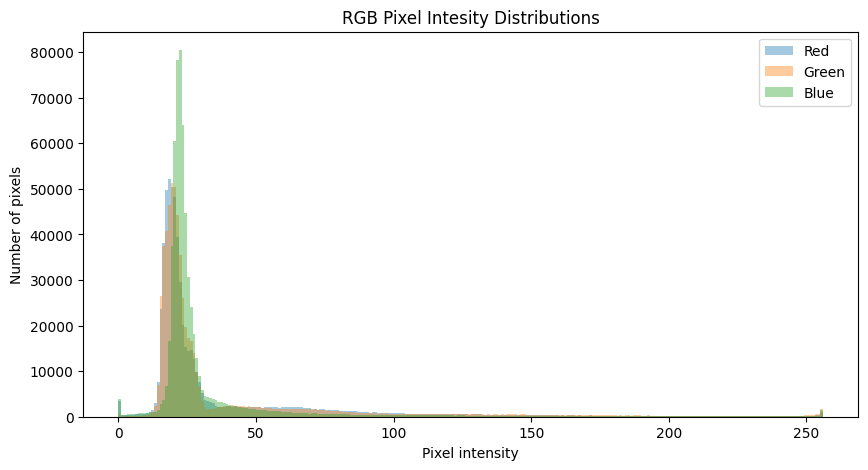

In [11]:
# Visualize the intensity distributions
fig, ax = plt.subplots(figsize=(10, 5))

for name, channel in channels.items():
    ax.hist(
        channel.ravel(), #change 2 dim channel to 1 dim view to build histogram
        bins=256,
        range=(0, 256),
        alpha=0.4,
        label=name
    )

ax.set_xlabel("Pixel intensity")
ax.set_ylabel("Number of pixels")
ax.set_title("RGB Pixel Intesity Distributions")
ax.legend()

plt.show()

In [12]:
## High concentration of peaks near zero.
## Background pixels can strongly influence our measurements

In [13]:
# Compare how many pixels fall into a dark intensity range
for name, channel in channels.items():
    dark_pixels = np.count_nonzero(channel < 30)
    total_pixels = channel.size

    percentage = (dark_pixels / total_pixels) * 100

    print(f"{name} : {percentage:.2f}% of pixels below 30")

Red : 71.44% of pixels below 30
Green : 72.85% of pixels below 30
Blue : 80.67% of pixels below 30


In [14]:
## The blue channel has the highest percentage of pixels below 30.  This explains why Blue has the highest peak near zero
## in the histogram

In [15]:
# Create a mask for green-channel pixels above a threshold
threshold = 20
green_mask = green > threshold

print("Mask shape: ", green_mask.shape)
print("Mask data type: ", green_mask.dtype)
print("Selected pixels: ", np.count_nonzero(green_mask))

Mask shape:  (492, 1272)
Mask data type:  bool
Selected pixels:  359581


In [16]:
## Threshold selection affects which biological structures we identify and what measurements we obtain

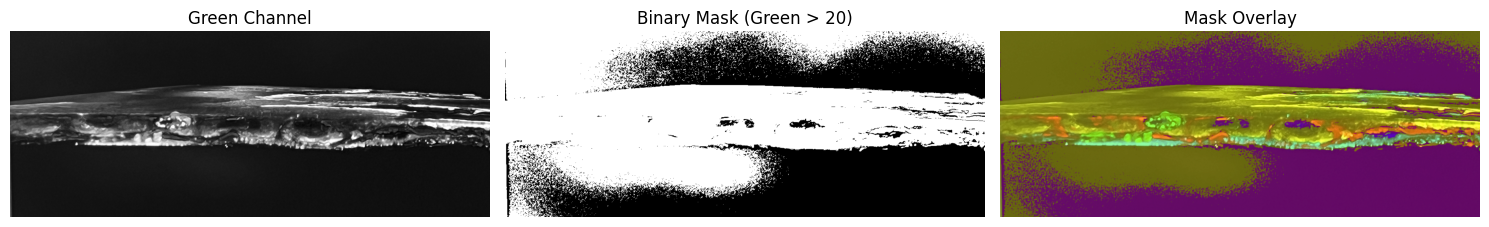

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(green, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Green Channel")

axes[1].imshow(green_mask, cmap="gray")
axes[1].set_title(f"Binary Mask (Green > {threshold})")

axes[2].imshow(image)
axes[2].imshow(green_mask, cmap="spring", alpha=0.35)
axes[2].set_title("Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
## False Positives: pixels selected even though they may not belong to the structures of interest

Mask shape:  (492, 1272)
Mask data type:  bool
Selected pixels:  122985


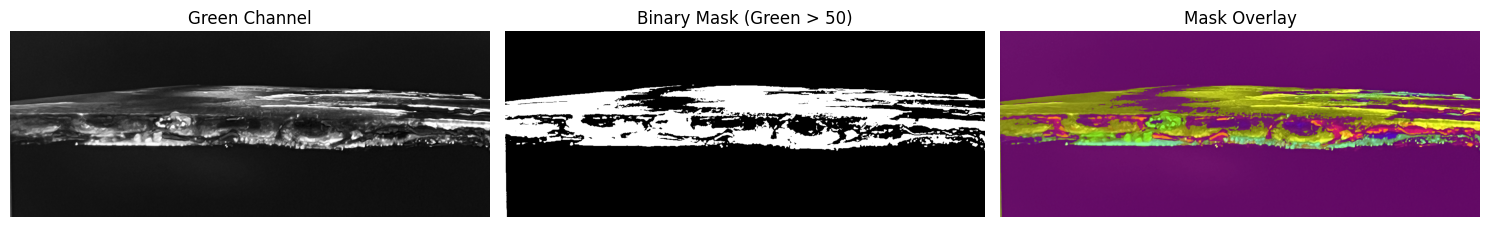

In [19]:
threshold = 50
green_mask = green > threshold

print("Mask shape: ", green_mask.shape)
print("Mask data type: ", green_mask.dtype)
print("Selected pixels: ", np.count_nonzero(green_mask))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(green, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Green Channel")

axes[1].imshow(green_mask, cmap="gray")
axes[1].set_title(f"Binary Mask (Green > {threshold})")

axes[2].imshow(image)
axes[2].imshow(green_mask, cmap="spring", alpha=0.35)
axes[2].set_title("Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [20]:
## Much of the background disappears while the mask retains substantial detail throughout the layered structure

Mask shape:  (492, 1272)
Mask data type:  bool
Selected pixels:  57755


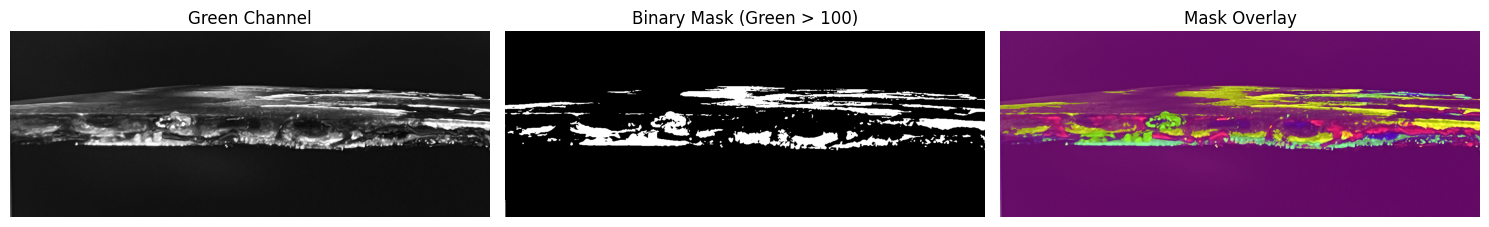

In [21]:
threshold = 100
green_mask = green > threshold

print("Mask shape: ", green_mask.shape)
print("Mask data type: ", green_mask.dtype)
print("Selected pixels: ", np.count_nonzero(green_mask))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(green, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Green Channel")

axes[1].imshow(green_mask, cmap="gray")
axes[1].set_title(f"Binary Mask (Green > {threshold})")

axes[2].imshow(image)
axes[2].imshow(green_mask, cmap="spring", alpha=0.35)
axes[2].set_title("Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
## False Negatives: meaningful structures that fall below the threshold and disappear from the mask

In [23]:
# Compare the percentage of pixels selected at each threshold
thresholds = [20, 50, 100]

for threshold in thresholds:
    mask = green > threshold

    selected_pixels = np.count_nonzero(mask)
    percentage = (selected_pixels / mask.size) * 100

    print(
        f"Threshold {threshold}: "
        f"{selected_pixels:,} pixels selected "
        f"({percentage:.2f}%)"
    )

Threshold 20: 359,581 pixels selected (57.46%)
Threshold 50: 122,985 pixels selected (19.65%)
Threshold 100: 57,755 pixels selected (9.23%)


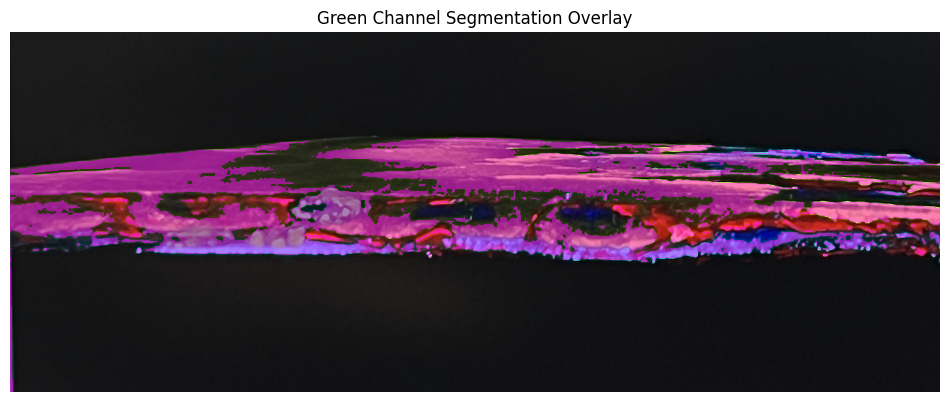

In [24]:
threshold = 50
green_mask = green > threshold

# Make unselected pixels transparent
masked_overlay = np.ma.masked_where(~green_mask, green_mask)

plt.figure(figsize=(12, 5))
plt.imshow(image)
plt.imshow(masked_overlay, cmap="spring", alpha=0.5)
plt.title("Green Channel Segmentation Overlay")
plt.axis("off")
plt.show()

Otsu threshold: 93
Selected pixels: 9.97%


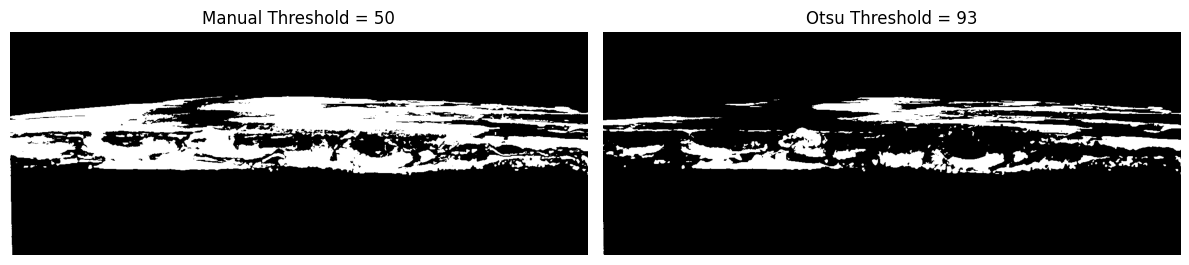

In [25]:
# Automatic Thresholding

from skimage.filters import threshold_otsu

# Calculate an automatic threshold
otsu_threshold = threshold_otsu(green)

# Create a binary mask
otsu_mask = green > otsu_threshold

print(f"Otsu threshold: {otsu_threshold}")
print(
    f"Selected pixels: "
    f"{np.count_nonzero(otsu_mask) / otsu_mask.size * 100:.2f}%"
)

# Compare manual and automatic masks
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(green > 50, cmap="gray")
axes[0].set_title("Manual Threshold = 50")

axes[1].imshow(otsu_mask, cmap="gray")
axes[1].set_title(f"Otsu Threshold = {otsu_threshold}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
manual_mask = green > 50
otsu_mask = green > otsu_threshold

# Pixels selected by manual threshold but not by Otsu
manual_only = manual_mask & ~otsu_mask

# Pixels selected by both methods
agreement = manual_mask & otsu_mask

print("Selected by both: ", np.count_nonzero(agreement))
print("Selected only by manual: ", np.count_nonzero(manual_only))

Selected by both:  62413
Selected only by manual:  60572


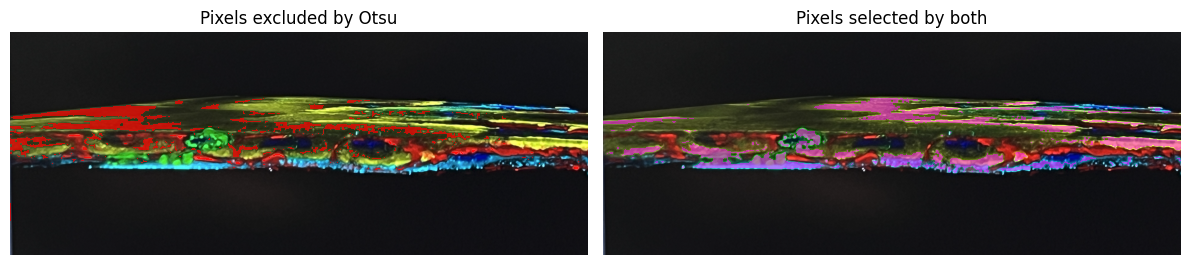

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(image)
axes[0].imshow(
    np.ma.masked_where(~manual_only, manual_only),
    cmap="autumn",
    alpha=0.7
)
axes[0].set_title("Pixels excluded by Otsu")

axes[1].imshow(image)
axes[1].imshow(
    np.ma.masked_where(~agreement, agreement),
    cmap="spring",
    alpha=0.5
)
axes[1].set_title("Pixels selected by both")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

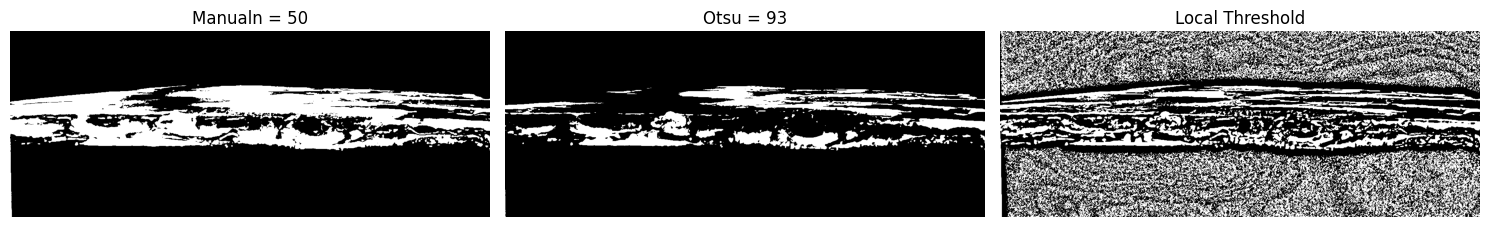

Local threshold selected: 44.56%


In [29]:
# Local Thresholding
from skimage.filters import threshold_local

# Calculate a local threshold for each pixel
# block-size: the threshold at each pixel is calculated using a neighborhood of approximately 51X51 pixels in size
local_threshold = threshold_local(green, block_size=51, method="gaussian")
local_mask = green > local_threshold

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(green > 50, cmap="gray")
axes[0].set_title("Manualn = 50")

axes[1].imshow(otsu_mask, cmap="gray")
axes[1].set_title("Otsu = 93")

axes[2].imshow(local_mask, cmap="gray")
axes[2].set_title("Local Threshold")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(
    "Local threshold selected: "
    f"{np.count_nonzero(local_mask) / local_mask.size * 100:.2f}%"
)
